<a href="https://colab.research.google.com/github/mitparekh8263/CV-2026-H11/blob/main/Practical_09/lab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Image Loading and Display

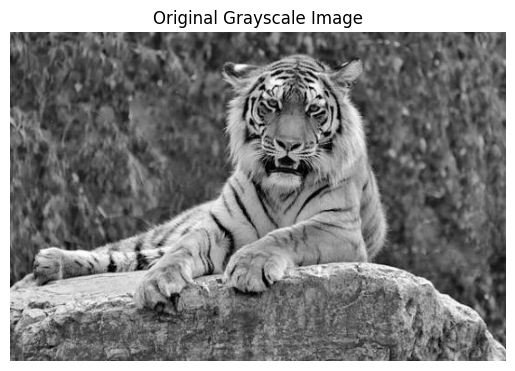

In [3]:
# Load grayscale image
image = cv2.imread("/content/tiger.jpg", cv2.IMREAD_GRAYSCALE)

# Display the gray image
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

Manual Sobel Filter (Edge Detection)

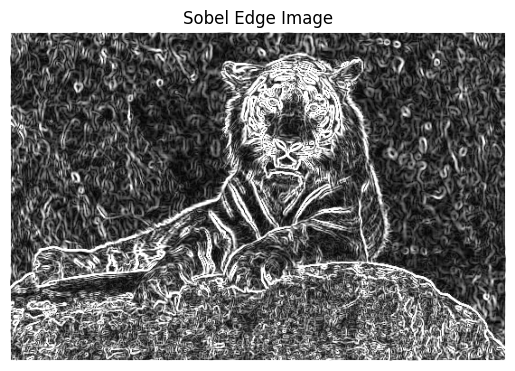

In [4]:
def sobel_filter(image):
  # horizonatal edage kernel
  sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])

  # horizonatal edage kernel
  sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])

  # add a 1 px black border around the image so 3x3 kernels can fit the edge pixels
  padded = np.pad(image, 1, mode="constant")
  rows, cols = image.shape

  # create empty canvases to store horizontal (gx) and vertical (gy) edge strengths
  gx = np.zeros((rows, cols), dtype=np.float32)
  gy = np.zeros((rows, cols), dtype=np.float32)

  # slide a 3x3 window over every single pixel of the image
  for i in range(rows):
      for j in range(cols):
          region = padded[i:i+3, j:j+3]
          # multiply the patch by the kernels and sums it up to get directional edge scores
          gx[i, j] = np.sum(region * sobel_x)
          gy[i, j] = np.sum(region * sobel_y)

  # get magnitude using gx, gy into absolute edge power
  magnitude = np.sqrt(gx**2 + gy**2)

  # ensures pixel values stay in standard color limits (0 to 255) & return magnitude in 8-bit foramt
  magnitude = np.clip(magnitude, 0, 255)
  return magnitude.astype(np.uint8)

# run custom filter function on our original image
edge_image = sobel_filter(image)

# display the processed edge map image
plt.imshow(edge_image, cmap="gray")
plt.title("Sobel Edge Image")
plt.axis("off")
plt.show()

Extracting Edge Coordinates

In [5]:
threshold = 100

# find (Y, X) array indices where the edge strength (g) > 100
edge_points = np.argwhere(edge_image > threshold)

# print how many total pixel locations passed the edge criteria
print("Number of edge points:", len(edge_points))

Number of edge points: 66573


Euclidean Hough Transform

In [6]:
def hough_euclidean(edge_image, threshold=100, angle_step=1):
  # get coordinates of pixels that qualify as active edges
  points = np.argwhere(edge_image > threshold)

  rows, cols = edge_image.shape

  # calculate the corner-to-corner diagonal (straight-line) distance
  diagonal = int(np.ceil(np.sqrt(rows**2 + cols**2)))

  # generate standard scanning angles from -90 to 89 degrees
  angles = np.arange(-90, 90, angle_step)

  # generate a spectrum of line distances from negative diagonal to positive diagonal
  distances = np.arange(-diagonal, diagonal + 1)

  # create an empty 2D accumulator / voting matrix to count overlapping line paths
  accumulator = np.zeros((len(distances), len(angles)), dtype=np.uint32)

  for y, x in points:
    # check every possible angle trajectory it could belong to...
    for angle_index, angle in enumerate(angles):
      theta = np.deg2rad(angle) # Converts degrees to radians

      # standard polar line equation: r = x*cos(θ) + y*sin(θ)
      r = round(x * np.cos(theta) + y * np.sin(theta))

      # shift negative distances forward so they map correctly to array index positions
      distance_index = r + diagonal

      # cast a vote into the grid slot for this line geometry
      accumulator[distance_index, angle_index] += 1

  return accumulator, distances, angles

# Executes the code block above
accumulator_e, distances_e, angles_e = hough_euclidean(edge_image, threshold=100)
print("Accumulator shape:", accumulator_e.shape)

Accumulator shape: (1319, 180)


Drawing Detected Lines

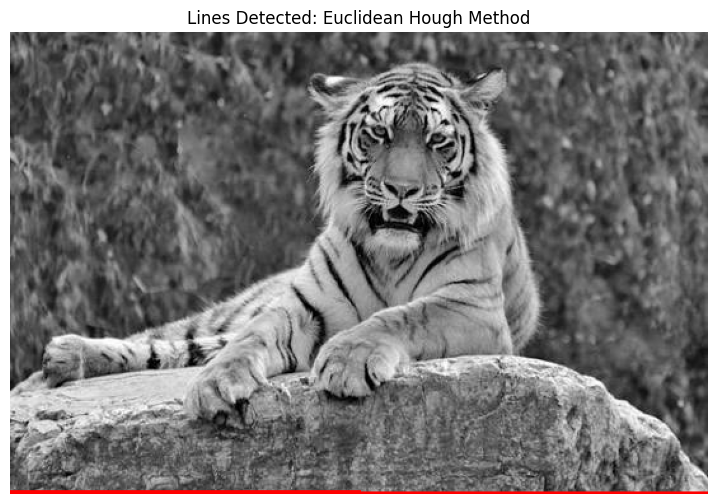

In [8]:
def draw_hough_lines(image, accumulator, distances, angles, num_lines=10, min_votes=80):
  # Converts grayscale backdrop back to color format (BGR) so red lines can be drawn on it
  output = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
  acc = accumulator.copy() # Clones the grid to avoid ruining the original dataset

  # Loops up to 10 times to draw the top 10 most prominent lines found
  for _ in range(num_lines):
    # Finds the highest-voted cell coordinate inside the 2D voting array
    index = np.unravel_index(np.argmax(acc), acc.shape)
    votes = acc[index]

    # Stops drawing if remaining lines are too faint or noisy
    if votes < min_votes:
        break

    # Translates array layout coordinates back into actual geometric lines (r, θ)
    distance_index, angle_index = index
    r = distances[distance_index]
    theta = np.deg2rad(angles[angle_index])

    # Basic trigonometry to locate the base anchor point (x0, y0) of the line
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * r
    y0 = b * r

    # Projects the point far off-screen in both directions to draw a full continuous line
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * a)
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * a)

    # Uses OpenCV to paint a solid red line (0, 0, 255) with a thickness of 2 pixels
    cv2.line(output, (x1, y1), (x2, y2), (0, 0, 255), 2)

    # Non-Maximum Suppression (NMS): Erases a 11x11 square around this peak inside the grid
    # This keeps the code from drawing 5 identical lines over the exact same pixel edge
    r_start = max(0, distance_index - 5)
    r_end = min(acc.shape[0], distance_index + 6)
    theta_start = max(0, angle_index - 5)
    theta_end = min(acc.shape[1], angle_index + 6)
    acc[r_start:r_end, theta_start:theta_end] = 0

    return output

# Generates and prints the final Euclidean output visual map
result_e = draw_hough_lines(image, accumulator_e, distances_e, angles_e, num_lines=10, min_votes=80)
plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(result_e, cv2.COLOR_BGR2RGB)) # Converts BGR to RGB for matplotlib
plt.title("Lines Detected: Euclidean Hough Method")
plt.axis("off")
plt.show()

Polar Hough Transform (Vectorized Optimization)

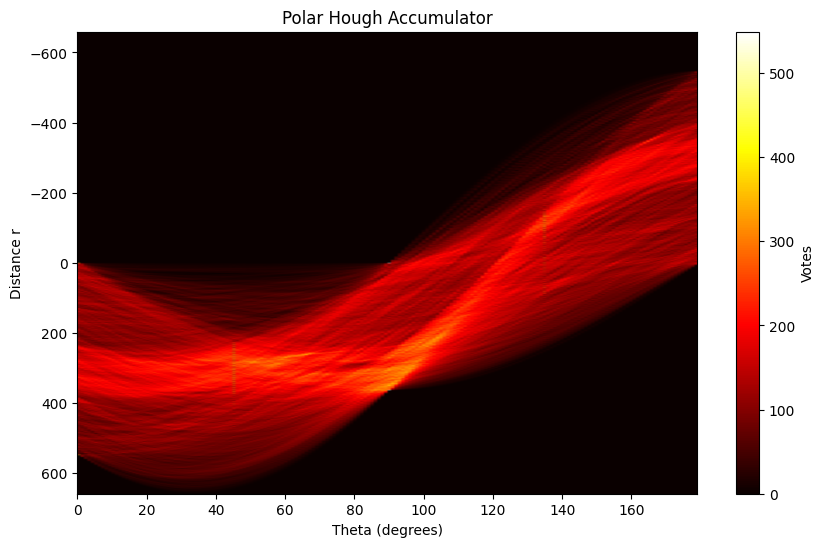

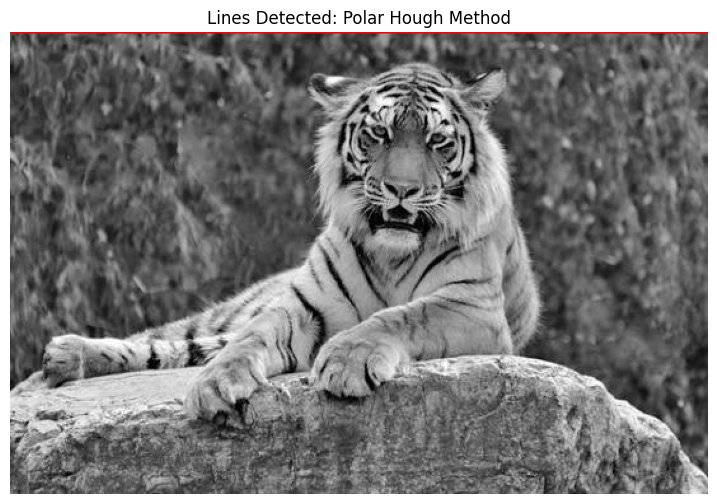

In [9]:
def hough_polar(edge_image, threshold=100, angle_step=1):
  rows, cols = edge_image.shape
  points = np.argwhere(edge_image > threshold)

  max_r = int(np.ceil(np.sqrt(rows**2 + cols**2)))
  # Scans from 0 to 180 degrees directly in radians
  angles = np.deg2rad(np.arange(0, 180, angle_step))
  r_values = np.arange(-max_r, max_r + 1)

  accumulator = np.zeros((len(r_values), len(angles)), dtype=np.uint32)

  # Calculates all sine and cosine angles up-front instead of doing it repeatedly inside a loop
  cos_values = np.cos(angles)
  sin_values = np.sin(angles)

  # Optimized loop: Instead of checking one single angle at a time,
  # it processes ALL angles for a given point at the exact same moment using matrix multiplication
  for y, x in points:
    r = x * cos_values + y * sin_values
    r_indices = np.rint(r).astype(int) + max_r # Rounds distances directly to index markers

    # Updates the full array profile layout
    for angle_index, r_index in enumerate(r_indices):
      accumulator[r_index, angle_index] += 1

  return accumulator, r_values, np.rad2deg(angles)

# Runs the faster Polar algorithm
accumulator_p, r_values_p, angles_p = hough_polar(edge_image, threshold=100)

# Displays the voting accumulator as a 2D Heatmap ("hot" color scheme)
# Bright white/yellow spots represent clean, straight continuous line paths in the image
plt.figure(figsize=(10, 6))
plt.imshow(accumulator_p, cmap="hot", aspect="auto",
           extent=[angles_p[0], angles_p[-1], r_values_p[-1], r_values_p[0]])
plt.xlabel("Theta (degrees)")
plt.ylabel("Distance r")
plt.title("Polar Hough Accumulator")
plt.colorbar(label="Votes")
plt.show()

# Renders the final drawn lines map using the Polar Hough results
result_p = draw_hough_lines(image, accumulator_p, r_values_p, angles_p, num_lines=10, min_votes=80)
plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(result_p, cv2.COLOR_BGR2RGB))
plt.title("Lines Detected: Polar Hough Method")
plt.axis("off")
plt.show()